In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
import seaborn as sns

### 1. Preparación de datos
- Base limpia de la Parte 1
- Variables: `log_App` (respuesta transformada), `hora` (0–23) y `franja` (5 franjas horarias definidas en el EDA de la Parte 2).
- Partición temporal 80/20: el entrenamiento es el tramo inicial y la validación el tramo más reciente.

In [2]:
ruta = "../Parte 1 - j-santaana/Base de datos procesada/energydata_limpio.csv"
df = pd.read_csv(ruta, parse_dates=["date"]).sort_values("date").reset_index(drop=True)
df = df.drop(columns="lights")
df["log_App"] = np.log(df["Appliances"])
df["hora"] = df["date"].dt.hour
df["franja"] = pd.cut(df["hora"], bins=[-1, 6, 8, 16, 21, 23],
                      labels=["Madrugada", "Mañana", "Día", "PicoVesp", "Noche"])

corte = int(0.8 * len(df))
train, test = df.iloc[:corte].copy(), df.iloc[corte:].copy()
print(f"Entrenamiento: {len(train)} ({train['date'].min()} → {train['date'].max()})")
print(f"Validación:    {len(test)} ({test['date'].min()} → {test['date'].max()})")

Entrenamiento: 15788 (2016-01-11 17:00:00 → 2016-04-30 08:10:00)
Validación:    3947 (2016-04-30 08:20:00 → 2016-05-27 18:00:00)


In [3]:
def vif(X):
    return pd.Series(np.diag(np.linalg.inv(X.corr().values)), index=X.columns).sort_values(ascending=False)

ambientales = [c for c in df.columns if c.startswith(("T", "RH_"))] + ["Press_mm_hg", "Windspeed", "Visibility"]
v_todos = vif(train[ambientales])
print(f"Con los {len(ambientales)} predictores ambientales: {(v_todos > 5).sum()} con VIF > 5 "
      f"(máx: {v_todos.index[0]} = {v_todos.iloc[0]:.0f})")

PREDICTORES = ["T1", "RH_1", "T_out", "RH_out", "Press_mm_hg", "Windspeed"]
print("\nVIF de los predictores seleccionados:")
print(vif(train[PREDICTORES]).round(2).to_string())

Con los 24 predictores ambientales: 19 con VIF > 5 (máx: T_out = 234)

VIF de los predictores seleccionados:
T_out          2.49
RH_out         1.91
RH_1           1.73
Windspeed      1.39
T1             1.34
Press_mm_hg    1.15


**Observación:** con los 24 predictores ambientales, 19 tienen VIF > 5 (máximo T_out = 234): las temperaturas y humedades de las distintas zonas miden casi lo mismo.
Se eligió un representante por bloque:
- **T1, RH_1** (cocina): representan las temperaturas y humedades interiores.
- **T_out, RH_out, Press_mm_hg, Windspeed**: condiciones exteriores.

Con el conjunto final, todos los VIF son ≤ 2,5.

### 3. Modelo preliminar y comparación
Respuesta: log(Appliances). Se ajustan por MCO tres modelos anidados con los 6 predictores:
- `m0`: sin hora.
- `m1`: hora agrupada en 5 franjas (base: madrugada) → **modelo preliminar**.
- `m_hora`: hora con 24 niveles (referencia).

Se comparan con pruebas F de modelos anidados y con AIC/BIC.

In [4]:
rhs = " + ".join(PREDICTORES)
m0     = smf.ols(f"log_App ~ {rhs}", train).fit()
m1     = smf.ols(f"log_App ~ {rhs} + C(franja)", train).fit()   # modelo preliminar
m_hora = smf.ols(f"log_App ~ {rhs} + C(hora)", train).fit()     # referencia

modelos = {"Sin hora": m0, "5 franjas": m1, "24 horas": m_hora}
print(pd.DataFrame({k: {"p'": m.df_model + 1, "R2_aj": m.rsquared_adj, "sigma": np.sqrt(m.scale),
                        "AIC": m.aic, "BIC": m.bic} for k, m in modelos.items()}).T.round(4))

print("\nSin hora vs 5 franjas")
print(sm.stats.anova_lm(m0, m1).round(4))
print("\n5 franjas vs 24 horas")
print(sm.stats.anova_lm(m1, m_hora).round(4))

             p'   R2_aj   sigma         AIC         BIC
Sin hora    7.0  0.0905  0.6454  30984.7568  31038.4258
5 franjas  11.0  0.2758  0.5759  27391.3302  27475.6673
24 horas   30.0  0.2973  0.5673  26933.9567  27163.9669

Sin hora vs 5 franjas
   df_resid        ssr  df_diff    ss_diff          F  Pr(>F)
0   15781.0  6573.4410      0.0        NaN        NaN     NaN
1   15777.0  5232.6917      4.0  1340.7494  1010.6177     0.0

5 franjas vs 24 horas
   df_resid        ssr  df_diff  ss_diff        F  Pr(>F)
0   15777.0  5232.6917      0.0      NaN      NaN     NaN
1   15758.0  5071.0567     19.0  161.635  26.4353     0.0


**Observaciones:**
- **24 horas vs 5 franjas:** las 24 horas ajustan algo mejor (F = 26,4; p < 0,001; menor AIC y BIC), pero la ganancia es acotada: R²_aj de 0,276 a 0,297 y σ̂ de 0,576 a 0,567. Las franjas logran el 89 % de la mejora con 4 parámetros en vez de 23.
- **Decisión:** se elige el modelo con franjas por interpretabilidad. Además, el diagnóstico muestra autocorrelación fuerte, por lo que la ventaja de las 24 horas está sobreestimada.

### 4. Coeficientes del modelo preliminar
Como la respuesta está en escala log, cada coeficiente se interpreta como un cambio porcentual:
**efecto % = 100·(e^β − 1)**, manteniendo fijos los demás regresores.
- Predictores continuos: cambio % en el consumo por cada unidad adicional.
- Franjas: diferencia % respecto de la madrugada

In [5]:
coefs = pd.DataFrame({"β": m1.params, "EE": m1.bse, "valor-p": m1.pvalues,
                      "efecto %": 100 * np.expm1(m1.params)})
print(coefs.loc[PREDICTORES].round(4))
print("\nEfecto de cada franja respecto de la magrugada(en porcentaje):")
print(coefs.filter(like="franja", axis=0)["efecto %"].round(1).to_string())

                  β      EE  valor-p  efecto %
T1           0.1058  0.0047   0.0000   11.1551
RH_1         0.0146  0.0017   0.0000    1.4755
T_out       -0.0193  0.0018   0.0000   -1.9113
RH_out      -0.0017  0.0005   0.0017   -0.1690
Press_mm_hg -0.0041  0.0006   0.0000   -0.4115
Windspeed    0.0027  0.0021   0.2102    0.2659

Efecto de cada franja respecto de la magrugada(en porcentaje):
C(franja)[T.Mañana]       46.0
C(franja)[T.Día]          89.7
C(franja)[T.PicoVesp]    129.0
C(franja)[T.Noche]        12.9


**Observaciones:**
- **Franjas (con el clima fijo):** respecto de la madrugada, el consumo es 129 % mayor en el pico vespertino (2,3 veces), 90 % mayor en el día (casi el doble), 46 % mayor en la mañana y 13 % mayor en la noche. Reproduce el perfil horario del EDA y son los efectos más grandes del modelo.
- **Predictores ambientales:** T1 tiene la asociación más fuerte (+11,2 % por °C; t ≈ 22), seguido de T_out (−1,9 % por °C) y RH_1 (+1,5 % por punto). La presión tiene un efecto pequeño (−0,4 % por mmHg).
- **No significativos o poco robustos:** Windspeed (p = 0,21). RH_out es significativa aquí (p = 0,002), pero no en el modelo con 24 horas, así que su efecto no es robusto.
- **Interpretación:** son asociaciones, no causas. T1 y RH_1 podrían reflejar el propio consumo: cocinar calienta y humedece la cocina.
- **Signo de T_out:** en la relación marginal (gráfico de la Parte 2) es positivo (+2,8 % por °C), pero se debe al ciclo diario. El signo de un coeficiente depende de los demás regresores cuando están correlacionados.
- Los valores-p son optimistas por la autocorrelación (ver diagnóstico).

In [6]:
sns.set_theme(style="whitegrid", rc={
    "grid.color": "#e6e6e3", "axes.edgecolor": "#c9c8c2",
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
})
AZUL, NARANJA, GRIS, TEXTO2 = "#00897b", "#e4572e", "#8a8984", "#52514e"

### Diagnóstico del modelo preliminar
Se evalúan los supuestos del modelo:
- **Función media:** test de Tukey y gráfico de residuos vs ajustados.
- **Varianza constante:** score test con Z = hora.
- **Normalidad:** gráfico QQ.
- **Atípicos e influencia:** leverage (hᵢᵢ > 2p′/n), residuos estudentizados con corrección de Bonferroni y distancia de Cook (Dᵢ ≈ 1 es preocupante).
- **Independencia:** Durbin–Watson (≈ 2 si no hay autocorrelación), Ljung–Box y ACF.

In [7]:
n, pp = int(m1.nobs), int(m1.df_model) + 1
infl = m1.get_influence()
r, h = infl.resid_studentized_internal, infl.hat_matrix_diag
t = r * np.sqrt((n - pp - 1) / (n - pp - r**2))      # residuo estudentizado
D = r**2 / pp * h / (1 - h)                           # distancia de Cook
p_bonf = np.minimum(1, 2 * n * stats.t.sf(np.abs(t), n - pp - 1))

t_tukey = smf.ols(f"{m1.model.formula} + I(aj**2)", train.assign(aj=m1.fittedvalues)).fit().tvalues.iloc[-1]

e2 = m1.resid**2
Z_hora = pd.get_dummies(train["hora"], drop_first=True).astype(float)
S = sm.OLS(e2 / e2.mean(), sm.add_constant(Z_hora)).fit().ess / 2

lb = sm.stats.acorr_ljungbox(m1.resid, lags=[144])

diagnostico = pd.Series({
    "Tukey: t": t_tukey,
    "Tukey: valor-p": 2 * stats.norm.sf(abs(t_tukey)),
    "Score test (Z = hora): S": S,
    "Score test: valor-p": stats.chi2.sf(S, Z_hora.shape[1]),
    "Leverage: máx h": h.max(),
    "Leverage: casos > 2p'/n": (h > 2 * pp / n).sum(),
    "Atípicos Bonferroni (p < 0.05)": (p_bonf < 0.05).sum(),
    "Cook: máx D": D.max(),
    "Durbin–Watson": sm.stats.durbin_watson(m1.resid),
    "ρ1 de residuos": m1.resid.autocorr(1),
    "Ljung–Box (144 retardos): valor-p": lb["lb_pvalue"].iloc[0],
})
print(diagnostico.round(4).to_string())

Tukey: t                                6.6718
Tukey: valor-p                          0.0000
Score test (Z = hora): S             2894.6516
Score test: valor-p                     0.0000
Leverage: máx h                         0.0052
Leverage: casos > 2p'/n               432.0000
Atípicos Bonferroni (p < 0.05)          2.0000
Cook: máx D                             0.0037
Durbin–Watson                           0.4797
ρ1 de residuos                          0.7601
Ljung–Box (144 retardos): valor-p       0.0000


In [8]:
print("Atípicos según Bonferroni:")
print(train.loc[p_bonf < 0.05, ["date", "Appliances"]])

top10 = train.index[np.argsort(D)[-10:]]
m1_sin = smf.ols(m1.model.formula, train.drop(index=top10)).fit()
print("\nCambio de los coeficientes al quitar los 10 casos con mayor D (en errores estándar):")
print(((m1_sin.params - m1.params) / m1.bse)[PREDICTORES].round(2).to_string())

Atípicos según Bonferroni:
                    date  Appliances
1821 2016-01-24 08:30:00         850
1823 2016-01-24 08:50:00         800

Cambio de los coeficientes al quitar los 10 casos con mayor D (en errores estándar):
T1             0.85
RH_1          -0.06
T_out         -0.38
RH_out        -0.20
Press_mm_hg   -0.48
Windspeed     -0.08


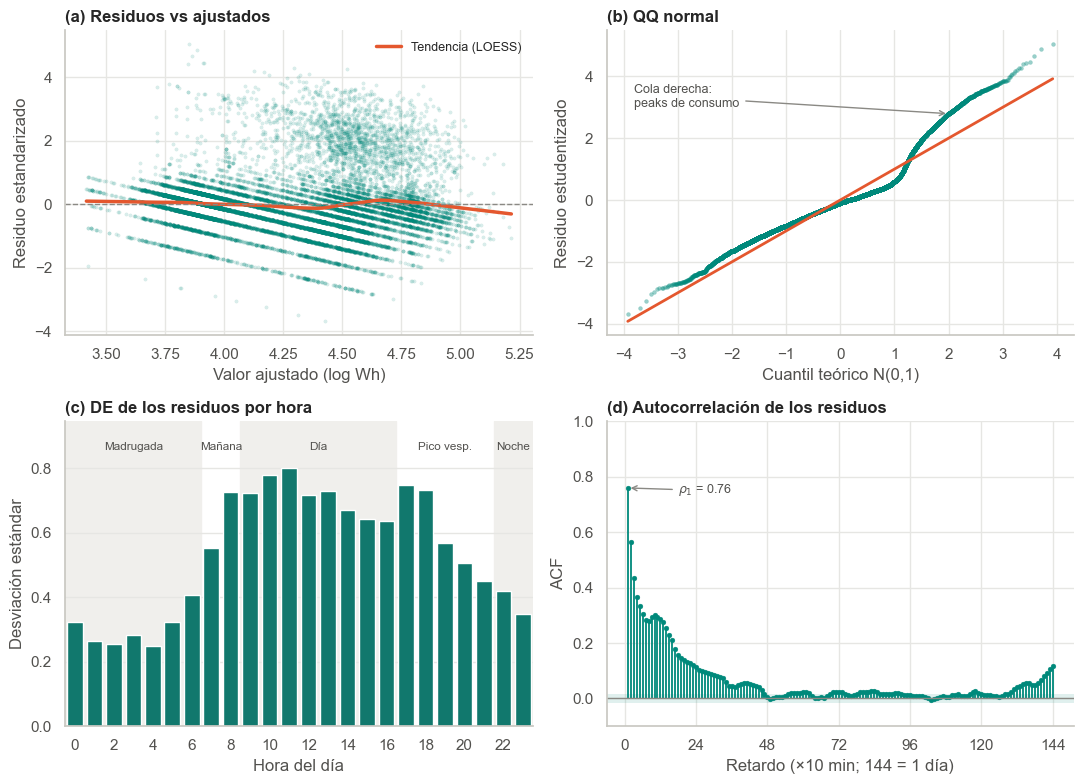

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(11, 8))

# (a) Residuos vs ajustados
ax = axs[0, 0]
sns.scatterplot(x=m1.fittedvalues, y=r, s=6, alpha=0.15, color=AZUL, edgecolor=None, ax=ax, rasterized=True)
s = sm.nonparametric.lowess(r, m1.fittedvalues, frac=0.3, it=0, delta=0.01 * np.ptp(m1.fittedvalues))
ax.plot(s[:, 0], s[:, 1], color=NARANJA, lw=2.5, label="Tendencia (LOESS)")
ax.axhline(0, color=GRIS, lw=1, ls="--")
ax.legend(loc="upper right", frameon=False, fontsize=9)
ax.set(title="(a) Residuos vs ajustados", xlabel="Valor ajustado (log Wh)", ylabel="Residuo estandarizado")

# (b) QQ normal
ax = axs[0, 1]
(osm, osr), _ = stats.probplot(t)
sns.scatterplot(x=osm, y=osr, s=8, alpha=0.4, color=AZUL, edgecolor=None, ax=ax, rasterized=True)
ax.plot(osm, osm, color=NARANJA, lw=2)
i = np.searchsorted(osm, 2.0)
ax.annotate("Cola derecha:\npeaks de consumo", xy=(osm[i], osr[i]), xytext=(-3.8, 3),
            color=TEXTO2, fontsize=9, arrowprops=dict(arrowstyle="->", color=GRIS))
ax.set(title="(b) QQ normal", xlabel="Cuantil teórico N(0,1)", ylabel="Residuo estudentizado")

# (c) DE de los residuos por hora, con las franjas de fondo
ax = axs[1, 0]
de = m1.resid.groupby(train["hora"]).std()
franjas = [(0, 6, "Madrugada"), (7, 8, "Mañana"), (9, 16, "Día"), (17, 21, "Pico vesp."), (22, 23, "Noche")]
for k, (a, b, nombre) in enumerate(franjas):
    if k % 2 == 0:
        ax.axvspan(a - 0.5, b + 0.5, color="#f0efec", zorder=0)
    ax.text((a + b) / 2, de.max() * 1.07, nombre, ha="center", fontsize=8.5, color=TEXTO2)
sns.barplot(x=de.index, y=de.values, color=AZUL, ax=ax, zorder=2)
ax.set_xticks(range(0, 24, 2))
ax.set(title="(c) DE de los residuos por hora", xlabel="Hora del día", ylabel="Desviación estándar",
       ylim=(0, de.max() * 1.18), xlim=(-0.5, 23.5))

# (d) Autocorrelación de los residuos
ax = axs[1, 1]
acf = sm.tsa.acf(m1.resid, nlags=144)
lags = np.arange(1, len(acf))
banda = 1.96 / np.sqrt(len(m1.resid))
ax.axhspan(-banda, banda, color=AZUL, alpha=0.12, lw=0)
ax.vlines(lags, 0, acf[1:], color=AZUL, lw=1.3)
sns.scatterplot(x=lags, y=acf[1:], s=12, color=AZUL, edgecolor=None, ax=ax)
ax.axhline(0, color=GRIS, lw=1)
ax.annotate(rf"$\rho_1$ = {acf[1]:.2f}", xy=(1, acf[1]), xytext=(18, acf[1] - 0.02),
            color=TEXTO2, fontsize=9, arrowprops=dict(arrowstyle="->", color=GRIS))
ax.set_xticks([0, 24, 48, 72, 96, 120, 144])
ax.set(title="(d) Autocorrelación de los residuos", xlabel="Retardo (×10 min; 144 = 1 día)",
       ylabel="ACF", ylim=(-0.1, 1))

sns.despine(fig)
fig.tight_layout()
fig.savefig("fig_diagnostico.png", dpi=300, bbox_inches="tight")
plt.show()

### Conclusiones del modelo preliminar
- **Modelo:** log(Appliances) ~ T1 + RH_1 + T_out + RH_out + Press_mm_hg + Windspeed + franja. Explica el 27,6 % de la variabilidad (R²_aj = 0,276).
- Entre las variables ambientales destacan la temperatura de la cocina (+11,2 % por °C) y la temperatura exterior (−1,9 % por °C).
- **Lo que se cumple:** no hay casos influyentes ni puntos de alto leverage, la función media es razonable.
- **Se observa:**
  1. Varianza no constante: depende de la hora.
  2. No normalidad: cola derecha por los peaks de consumo.
  3. **Autocorrelación fuerte (DW = 0,48):** los errores estándar de MCO están subestimados, así que los valores-p y las pruebas F son optimistas.